In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = yf.download("SPY", start="2000-01-01", auto_adjust=True, multi_level_index=False)
df.to_csv("spy_daily.csv")

df = pd.read_csv("spy_daily.csv", index_col=0, parse_dates=True)

print(df.head())
print(df.index.dtype)   # doit afficher datetime64[ns]
print(df.isna().sum())
print(len(df))

[*********************100%***********************]  1 of 1 completed

                Close       High        Low       Open    Volume
Date                                                            
2000-01-03  90.906960  92.664937  89.930305  92.664937   8164300
2000-01-04  87.351959  90.047525  87.283593  89.715463   8089800
2000-01-05  87.508224  88.465346  85.789313  87.469158  12177900
2000-01-06  86.101875  88.445847  86.101875  87.273861   6227200
2000-01-07  91.102325  91.102325  87.547303  87.703568   8066500
datetime64[ns]
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64
6733


Buy and hold rendement annuel   8.6% | vol 19.2% | Sharpe 0.53 | drawdown max -55.2%
MA50         rendement annuel   2.0% | vol 10.8% | Sharpe 0.24 | drawdown max -46.8%
Nombre de trades : 465


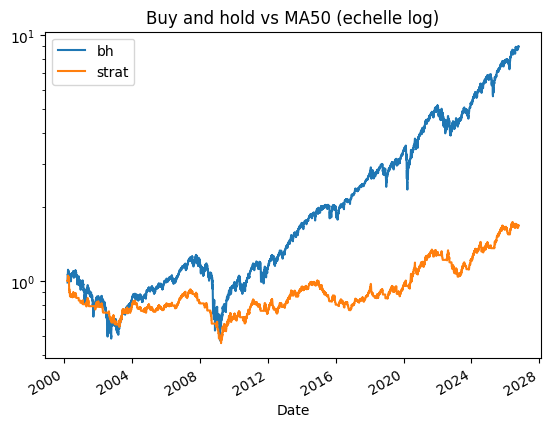

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

FRAIS = 0.001  # 0,1 % par changement de position

# 1) Signal : 1 si prix > MA50, sinon 0
df["ma50"] = df["Close"].rolling(50).mean()
df["signal"] = (df["Close"] > df["ma50"]).astype(int)

# 2) Position du jour = signal de la veille (evite le look-ahead bias)
df["position"] = df["signal"].shift(1)

# 3) Rendements
df["rend"] = df["Close"].pct_change()
trades = df["position"].diff().abs()           # 1 quand on change de position
df["rend_strat"] = df["position"] * df["rend"] - trades * FRAIS

# On enleve les 50 premiers jours (pas de MA50 disponible)
d = df.dropna(subset=["ma50", "position"]).copy()

# 4) Courbes de capital
d["bh"] = (1 + d["rend"]).cumprod()
d["strat"] = (1 + d["rend_strat"]).cumprod()

# 5) Metriques
def metriques(rend, nom):
    capital = (1 + rend).cumprod()
    annuel = capital.iloc[-1] ** (252 / len(rend)) - 1
    vol = rend.std() * np.sqrt(252)
    sharpe = rend.mean() / rend.std() * np.sqrt(252)
    drawdown = (capital / capital.cummax() - 1).min()
    print(f"{nom:12s} rendement annuel {annuel:6.1%} | vol {vol:5.1%} | "
          f"Sharpe {sharpe:4.2f} | drawdown max {drawdown:6.1%}")

metriques(d["rend"], "Buy and hold")
metriques(d["rend_strat"], "MA50")
print("Nombre de trades :", int(trades.loc[d.index].sum()))

d[["bh", "strat"]].plot(logy=True)
plt.title("Buy and hold vs MA50 (echelle log)")
plt.show()

MA20         rendement annuel   0.8% | vol 11.2% | Sharpe 0.13 | drawdown max -44.7%
  trades : 773
MA50         rendement annuel   2.0% | vol 10.8% | Sharpe 0.24 | drawdown max -46.8%
  trades : 465
MA100        rendement annuel   5.3% | vol 11.0% | Sharpe 0.53 | drawdown max -37.9%
  trades : 281
MA200        rendement annuel   7.0% | vol 11.1% | Sharpe 0.66 | drawdown max -22.4%
  trades : 165


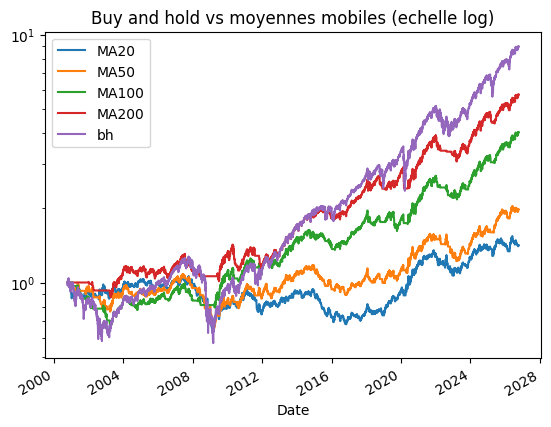

In [ ]:
def backtest(df, fenetre=50, frais=0.001):
    d = df.copy()
    d["ma"] = d["Close"].rolling(fenetre).mean()
    d["position"] = (d["Close"] > d["ma"]).astype(int).shift(1)
    d["rend"] = d["Close"].pct_change()
    trades = d["position"].diff().abs()
    d["rend_strat"] = d["position"] * d["rend"] - trades * frais
    d = d.dropna(subset=["ma", "position"])
    return d, int(trades.loc[d.index].sum())

courbes = pd.DataFrame()

for n in [20, 50, 100, 200]:
    d, nb = backtest(df, fenetre=n)
    metriques(d["rend_strat"], f"MA{n}")
    print("  trades :", nb)
    courbes[f"MA{n}"] = (1 + d["rend_strat"]).cumprod()   # ici on cree la colonne

# Buy and hold sur la meme periode que la MA la plus longue
rend_bh = df["Close"].pct_change().loc[courbes.dropna().index]
courbes["bh"] = (1 + rend_bh).cumprod()

courbes = courbes.dropna()
courbes = courbes / courbes.iloc[0]   # on repart tous de 1 a la meme date

courbes.plot(logy=True)
plt.title("Buy and hold vs moyennes mobiles (echelle log)")
plt.show()

SMA200       rendement annuel   7.0% | vol 11.1% | Sharpe 0.66 | drawdown max -22.4%
  trades : 165
EMA200       rendement annuel   5.1% | vol 11.3% | Sharpe 0.49 | drawdown max -29.4%
  trades : 215
VWMA200      rendement annuel   5.3% | vol 11.4% | Sharpe 0.51 | drawdown max -29.5%
  trades : 213
Buy and hold rendement annuel   8.8% | vol 19.1% | Sharpe 0.54 | drawdown max -55.2%


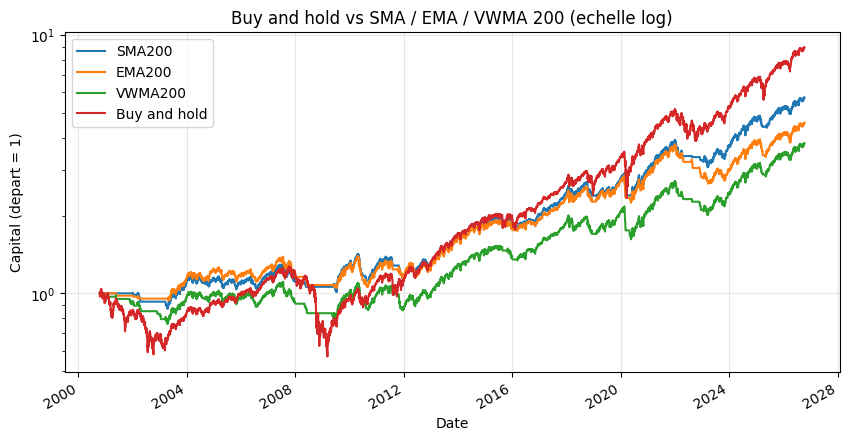

In [ ]:
def backtest(df, fenetre=200, frais=0.001, type_moy="sma"):
    d = df.copy()
    if type_moy == "sma":
        d["ma"] = d["Close"].rolling(fenetre).mean()
    elif type_moy == "ema":
        d["ma"] = d["Close"].ewm(span=fenetre, adjust=False).mean()
    elif type_moy == "vwma":
        d["ma"] = (d["Close"] * d["Volume"]).rolling(fenetre).sum() / d["Volume"].rolling(fenetre).sum()

    d["position"] = (d["Close"] > d["ma"]).astype(int).shift(1)
    d["rend"] = d["Close"].pct_change()
    trades = d["position"].diff().abs()
    d["rend_strat"] = d["position"] * d["rend"] - trades * frais
    d = d.dropna(subset=["ma", "position"])
    return d, int(trades.loc[d.index].sum())

courbes = pd.DataFrame()

for t in ["sma", "ema", "vwma"]:
    d, nb = backtest(df, fenetre=200, type_moy=t)
    metriques(d["rend_strat"], f"{t.upper()}200")
    print("  trades :", nb)
    courbes[f"{t.upper()}200"] = (1 + d["rend_strat"]).cumprod()

# Buy and hold sur les memes dates
rend_bh = df["Close"].pct_change().loc[courbes.dropna().index]
courbes["Buy and hold"] = (1 + rend_bh).cumprod()

# Dates communes + depart a 1 pour tout le monde
courbes = courbes.dropna()
courbes = courbes / courbes.iloc[0]

metriques(rend_bh, "Buy and hold")

courbes.plot(logy=True, figsize=(10, 5))
plt.title("Buy and hold vs SMA / EMA / VWMA 200 (echelle log)")
plt.ylabel("Capital (depart = 1)")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
df_g = yf.download("GLD", start="2000-01-01", auto_adjust=True, multi_level_index=False)
df_g.to_csv("GLD_daily.csv")

df_g = pd.read_csv("GLD_daily.csv", index_col=0, parse_dates=True)

print(df_g.head())
print(df_g.index.dtype)
print(df_g.isna().sum())
print(len(df_g))

[*********************100%***********************]  1 of 1 completed

                Close       High        Low       Open    Volume
Date                                                            
2004-11-18  44.380001  44.490002  44.070000  44.430000   5992000
2004-11-19  44.779999  44.919998  44.470001  44.490002  11655300
2004-11-22  44.950001  44.970001  44.740002  44.750000  11996000
2004-11-23  44.750000  44.919998  44.720001  44.880001   3169200
2004-11-24  45.049999  45.049999  44.790001  44.930000   6105100
datetime64[ns]
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64
5507


GLD SMA50    rendement annuel   4.3% | vol 14.0% | Sharpe 0.37 | drawdown max -44.0%
  trades : 392
GLD SMA100   rendement annuel   5.5% | vol 14.6% | Sharpe 0.44 | drawdown max -42.6%
  trades : 256
GLD SMA200   rendement annuel   7.4% | vol 15.2% | Sharpe 0.55 | drawdown max -37.1%
  trades : 162
GLD B&H      rendement annuel  10.8% | vol 18.5% | Sharpe 0.65 | drawdown max -45.6%


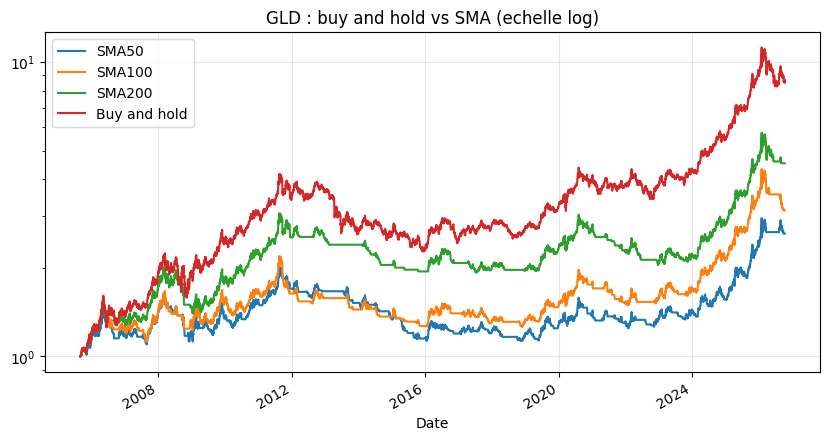

In [ ]:
courbes_g = pd.DataFrame()

for n in [50, 100, 200]:
    d, nb = backtest(df_g, fenetre=n, type_moy="sma")
    metriques(d["rend_strat"], f"GLD SMA{n}")
    print("  trades :", nb)
    courbes_g[f"SMA{n}"] = (1 + d["rend_strat"]).cumprod()

# Buy and hold sur les memes dates
rend_bh_g = df_g["Close"].pct_change().loc[courbes_g.dropna().index]
courbes_g["Buy and hold"] = (1 + rend_bh_g).cumprod()

courbes_g = courbes_g.dropna()
courbes_g = courbes_g / courbes_g.iloc[0]

metriques(rend_bh_g, "GLD B&H")

courbes_g.plot(logy=True, figsize=(10, 5))
plt.title("GLD : buy and hold vs SMA (echelle log)")
plt.grid(True, alpha=0.3)
plt.show()

GLD SMA200   rendement annuel   7.4% | vol 15.2% | Sharpe 0.55 | drawdown max -37.1%
  trades : 162
GLD EMA200   rendement annuel   7.8% | vol 15.3% | Sharpe 0.57 | drawdown max -29.5%
  trades : 172
GLD VWMA200  rendement annuel   7.4% | vol 15.0% | Sharpe 0.55 | drawdown max -35.0%
  trades : 160
GLD B&H      rendement annuel  10.8% | vol 18.5% | Sharpe 0.65 | drawdown max -45.6%


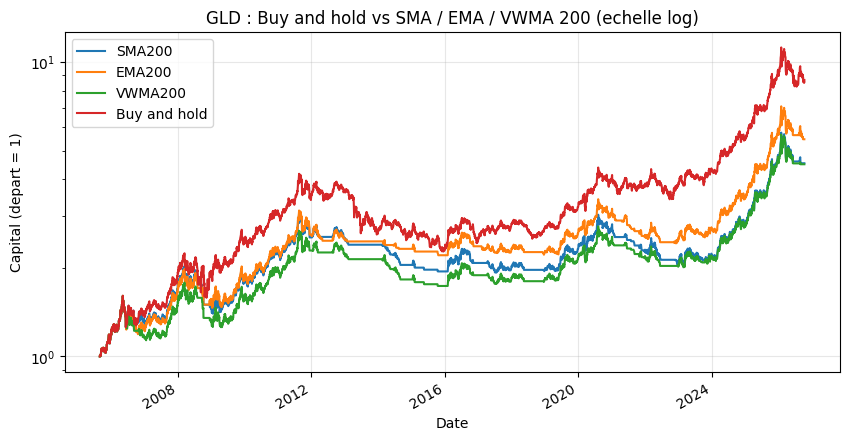

In [ ]:
courbes_g = pd.DataFrame()

for t in ["sma", "ema", "vwma"]:
    d_g, nb = backtest(df_g, fenetre=200, type_moy=t)
    metriques(d_g["rend_strat"], f"GLD {t.upper()}200")
    print("  trades :", nb)
    courbes_g[f"{t.upper()}200"] = (1 + d_g["rend_strat"]).cumprod()

# Buy and hold sur les memes dates
rend_bh_g = df_g["Close"].pct_change().loc[courbes_g.dropna().index]
courbes_g["Buy and hold"] = (1 + rend_bh_g).cumprod()

# Dates communes + depart a 1 pour tout le monde
courbes_g = courbes_g.dropna()
courbes_g = courbes_g / courbes_g.iloc[0]

metriques(rend_bh_g, "GLD B&H")

courbes_g.plot(logy=True, figsize=(10, 5))
plt.title("GLD : Buy and hold vs SMA / EMA / VWMA 200 (echelle log)")
plt.ylabel("Capital (depart = 1)")
plt.grid(True, alpha=0.3)
plt.show()